# EDA Analysis

In [1]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("HospitalCommandCenter_EDA")
    .getOrCreate()
)

print("Spark version:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/ubuntu/hospital-eda-env/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/22 22:47:11 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.3.0


In [43]:

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt

spark = SparkSession.builder \
    .master("local[2]") \
    .appName("HospitalCommandCenter_EDA") \
    .getOrCreate()

print("Spark version:", spark.version)


Spark version: 4.3.0


## Load Raw FHIR Healthcare Datasets into PySpark

In [44]:

path = "/home/ubuntu/hospital-command-center/data/raw/"

patients = spark.read.json(path + "Patient-0.ndjson")

encounters = spark.read.json([
    path + "Encounter-0.ndjson",
    path + "Encounter-1.ndjson"
])

conditions = spark.read.json(path + "Condition-0.ndjson")

procedures = spark.read.json([
    path + "Procedure-0.ndjson",
    path + "Procedure-1.ndjson"
])

medications = spark.read.json(path + "MedicationRequest-0.ndjson")


## Dataset Quality Assessment: Record Counts, Duplicates, and Missing IDs

In [45]:

datasets = {
    "Patients": patients,
    "Encounters": encounters,
    "Conditions": conditions,
    "Procedures": procedures,
    "Medications": medications
}

results = []

for name, df in datasets.items():
    total = df.count()
    unique = df.select("id").distinct().count()
    missing = df.filter("id IS NULL").count()

    results.append([name, total, total - unique, missing])

summary = pd.DataFrame(
    results,
    columns=["Dataset", "Records", "Duplicates", "Missing IDs"]
)

display(summary)


,Dataset,Records,Duplicates,Missing IDs
0,Patients,109,0,0
1,Encounters,4513,0,0
2,Conditions,3072,0,0
3,Procedures,6808,0,0
4,Medications,3570,0,0


## Create Encounter-Level Dataset with Procedure and Medication Counts

In [48]:

encounters_clean = encounters.select(
    F.col("id").alias("encounter_id"),
    F.col("class.code").alias("type"),
    F.to_timestamp("period.start").alias("start")
)

procedure_counts = procedures.select(
    F.regexp_extract("encounter.reference", r"([^/]+)$", 1).alias("encounter_id")
).filter("encounter_id != ''").groupBy("encounter_id").count()

procedure_counts = procedure_counts.withColumnRenamed("count", "procedures")

medication_counts = medications.select(
    F.regexp_extract("encounter.reference", r"([^/]+)$", 1).alias("encounter_id")
).filter("encounter_id != ''").groupBy("encounter_id").count()

medication_counts = medication_counts.withColumnRenamed("count", "medications")


eda = encounters_clean.join(procedure_counts, "encounter_id", "left")
eda = eda.join(medication_counts, "encounter_id", "left")

eda = eda.fillna(0, subset=["procedures", "medications"])

display(eda.limit(10).toPandas())


/home/ubuntu/hospital-eda-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/ubuntu/hospital-eda-env/lib/python3.12/site-packages/pyspark/sql/pandas/types.py:786: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,encounter_id,type,start,procedures,medications
0,361f6376-4e0d-b30f-bb20-700bba4af2a5,AMB,2002-07-31 21:33:51,0,4
1,c35a2988-fbd9-3762-57fb-65910f4fc591,AMB,2003-04-05 18:18:33,1,0
2,e528f8d5-b47e-ef4e-3847-e302bf1a76eb,AMB,2001-08-12 06:22:26,1,0
3,17bb4ec5-b142-f72d-9fe7-0cc6abe6d1a0,AMB,2017-04-27 16:49:02,6,3
4,c86ec94d-73cf-28c4-f42f-6877535984b8,AMB,2012-10-11 18:22:32,2,0
5,3bfe9162-6500-cd2e-d782-1716d78c094c,EMER,1992-11-08 06:22:51,0,0
6,4707d034-f465-3896-3b18-ba6eda26da60,EMER,2020-08-29 02:17:23,0,0
7,20d5581c-0881-dd17-eccb-ce5225207263,AMB,2019-03-06 12:29:51,1,0
8,87da0e33-6574-59a4-ceed-182b462582f4,AMB,2002-02-17 05:37:31,0,0
9,69dc9514-ae4f-17fa-6710-190cd336c029,IMP,2021-03-14 18:18:31,1,2


## Overall Clinical Workload Summary

In [49]:

summary = eda.agg(
    F.count("*").alias("Total Encounters"),
    F.round(F.avg("procedures"), 2).alias("Avg Procedures"),
    F.round(F.avg("medications"), 2).alias("Avg Medications"),
    F.sum((F.col("procedures") > 0).cast("int")).alias("With Procedures"),
    F.sum((F.col("medications") > 0).cast("int")).alias("With Medications")
)

display(summary.toPandas().T)


/home/ubuntu/hospital-eda-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,0
Total Encounters,4513.00
Avg Procedures,1.51
Avg Medications,0.79
With Procedures,2078.00
With Medications,1788.00


/home/ubuntu/hospital-eda-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


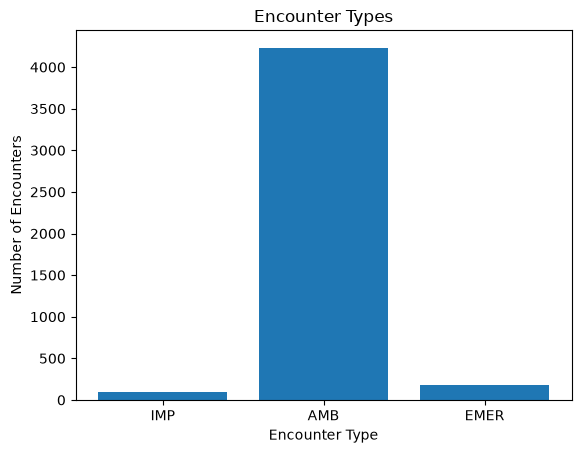

In [50]:

types = eda.groupBy("type").count().toPandas()

plt.bar(types["type"], types["count"])
plt.title("Encounter Types")
plt.xlabel("Encounter Type")
plt.ylabel("Number of Encounters")
plt.show()


/home/ubuntu/hospital-eda-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


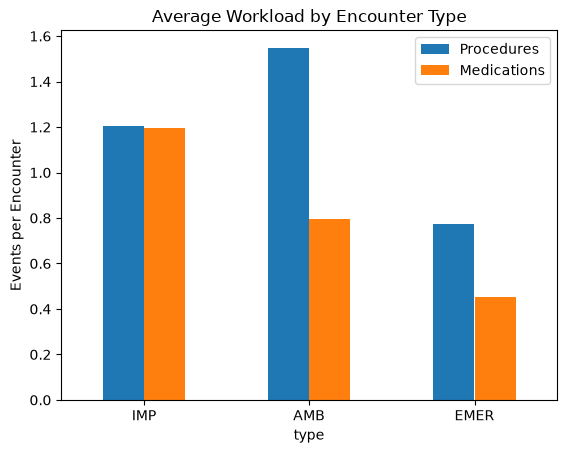

In [51]:

workload = eda.groupBy("type").agg(
    F.avg("procedures").alias("Procedures"),
    F.avg("medications").alias("Medications")
).toPandas()

workload.plot(
    x="type",
    y=["Procedures", "Medications"],
    kind="bar"
)

plt.title("Average Workload by Encounter Type")
plt.ylabel("Events per Encounter")
plt.xticks(rotation=0)
plt.show()


/home/ubuntu/hospital-eda-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


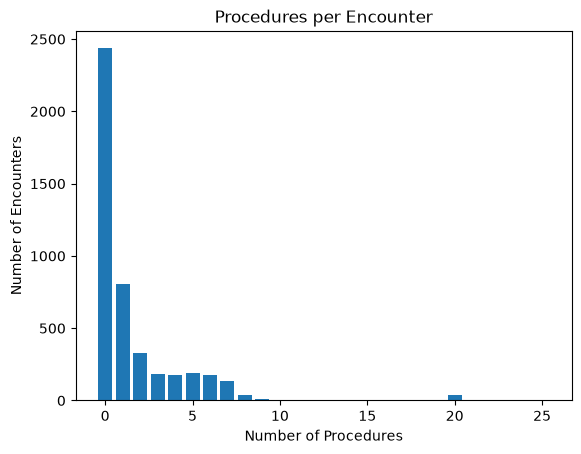

In [53]:

distribution = eda.groupBy("procedures").count().toPandas()

plt.bar(distribution["procedures"], distribution["count"])
plt.title("Procedures per Encounter")
plt.xlabel("Number of Procedures")
plt.ylabel("Number of Encounters")
plt.show()


/home/ubuntu/hospital-eda-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/ubuntu/hospital-eda-env/lib/python3.12/site-packages/pyspark/sql/pandas/types.py:786: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


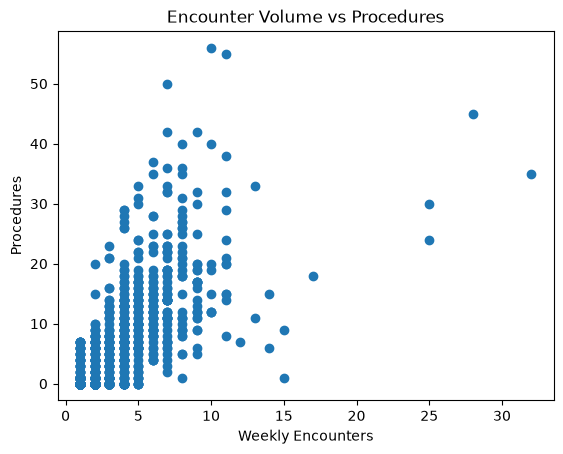

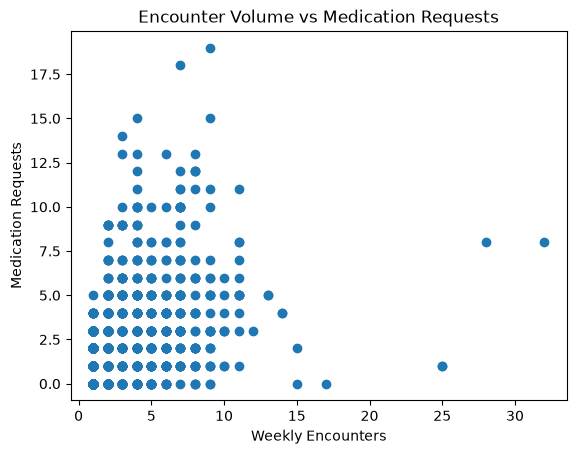

In [54]:

weekly = eda.groupBy(
    F.date_trunc("week", "start").alias("week")
).agg(
    F.count("*").alias("encounters"),
    F.sum("procedures").alias("procedures"),
    F.sum("medications").alias("medications")
)

weekly_pd = weekly.toPandas()

plt.scatter(weekly_pd["encounters"], weekly_pd["procedures"])
plt.title("Encounter Volume vs Procedures")
plt.xlabel("Weekly Encounters")
plt.ylabel("Procedures")
plt.show()

plt.scatter(weekly_pd["encounters"], weekly_pd["medications"])
plt.title("Encounter Volume vs Medication Requests")
plt.xlabel("Weekly Encounters")
plt.ylabel("Medication Requests")
plt.show()



## Compare Clinical Workload Across Selected Weeks

In [55]:

weeks = ["2020-07-13", "2021-03-08", "2022-01-03", "2022-07-04"]

comparison = weekly.filter(
    F.date_format("week", "yyyy-MM-dd").isin(weeks)
).orderBy("week")

display(comparison.toPandas())


/home/ubuntu/hospital-eda-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/ubuntu/hospital-eda-env/lib/python3.12/site-packages/pyspark/sql/pandas/types.py:786: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,week,encounters,procedures,medications
0,2020-07-13,7,19,10
1,2021-03-08,8,1,2
2,2022-01-03,9,13,3
3,2022-07-04,7,25,3


## Top 10 Diagnoses Associated with the Highest Average Procedure Counts

In [56]:

diagnoses = conditions.select(
    F.regexp_extract("encounter.reference", r"([^/]+)$", 1).alias("encounter_id"),
    F.col("code.coding")[0]["display"].alias("diagnosis")
).dropDuplicates().filter("encounter_id != ''")

diagnosis_data = diagnoses.join(
    eda.select("encounter_id", "procedures"),
    "encounter_id"
)

diagnosis_summary = diagnosis_data.groupBy("diagnosis").agg(
    F.count("*").alias("encounters"),
    F.round(F.avg("procedures"), 2).alias("avg_procedures")
)

top_diagnoses = diagnosis_summary.filter(
    F.col("encounters") >= 10
).orderBy(F.desc("avg_procedures")).limit(10)

display(top_diagnoses.toPandas())


/home/ubuntu/hospital-eda-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,diagnosis,encounters,avg_procedures
0,Normal pregnancy,67,12.10
1,Reports of violence in the environment (finding),46,4.70
2,Unhealthy alcohol drinking behavior (finding),15,4.60
3,Not in labor force (finding),80,4.35
4,Part-time employment (finding),176,3.94
5,Social isolation (finding),101,3.30
6,Anemia (disorder),29,3.10
7,Victim of intimate partner abuse (finding),76,2.86
8,Fetus with unknown complication,10,2.50
9,Stress (finding),398,2.41


In [57]:

patient_ages = patients.select(
    F.col("id").alias("patient_id"),
    F.to_date("birthDate").alias("birth_date")
)

encounter_ages = encounters.select(
    F.col("id").alias("encounter_id"),
    F.regexp_extract("subject.reference", r"([^/]+)$", 1).alias("patient_id")
)

age_data = eda.join(encounter_ages, "encounter_id")
age_data = age_data.join(patient_ages, "patient_id")

age_data = age_data.withColumn(
    "age",
    F.floor(F.months_between(F.to_date("start"), "birth_date") / 12)
)

age_data = age_data.filter("age >= 0 AND age <= 120")

age_data = age_data.withColumn(
    "age_group",
    F.when(F.col("age") < 18, "0-17")
     .when(F.col("age") < 40, "18-39")
     .when(F.col("age") < 65, "40-64")
     .otherwise("65+")
)


/home/ubuntu/hospital-eda-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,age_group,Encounters,Procedures,Medications
0,0-17,835,0.76,0.45
1,18-39,1966,1.57,0.80
2,40-64,1471,1.72,0.83
3,65+,241,2.29,1.73


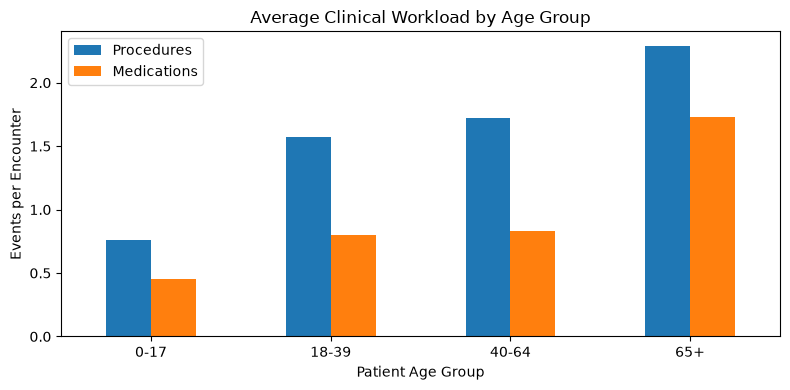

In [58]:

age_workload = age_data.groupBy("age_group").agg(
    F.count("*").alias("Encounters"),
    F.round(F.avg("procedures"), 2).alias("Procedures"),
    F.round(F.avg("medications"), 2).alias("Medications")
).orderBy("age_group")

age_pd = age_workload.toPandas()

display(age_pd)

age_pd.plot(
    x="age_group",
    y=["Procedures", "Medications"],
    kind="bar",
    figsize=(8, 4)
)

plt.title("Average Clinical Workload by Age Group")
plt.xlabel("Patient Age Group")
plt.ylabel("Events per Encounter")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


/home/ubuntu/hospital-eda-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


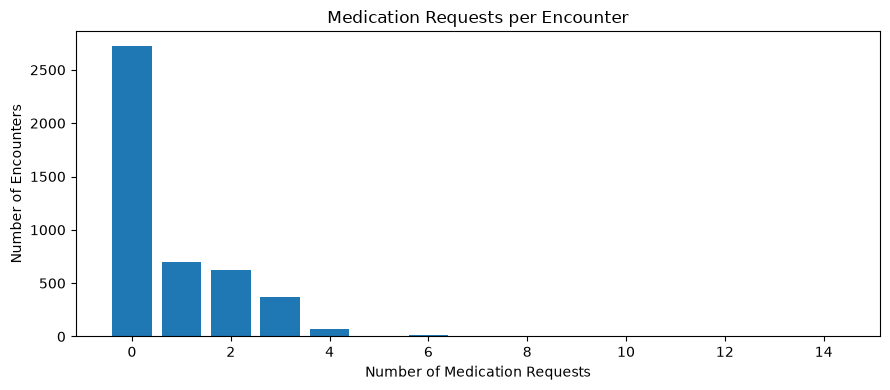

In [59]:

med_distribution = eda.groupBy("medications").count().orderBy("medications")

med_pd = med_distribution.toPandas()

plt.figure(figsize=(9, 4))
plt.bar(med_pd["medications"], med_pd["count"])

plt.title("Medication Requests per Encounter")
plt.xlabel("Number of Medication Requests")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()


/home/ubuntu/hospital-eda-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


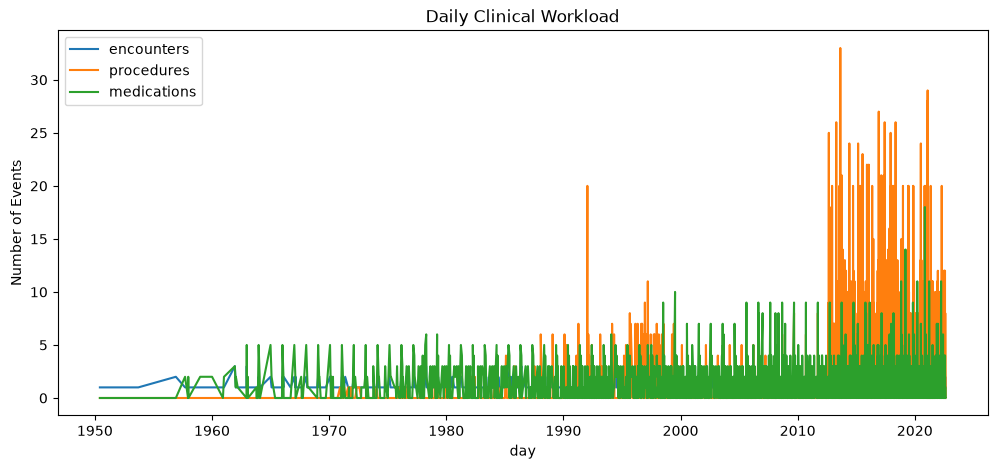

In [63]:

from pyspark.sql import functions as F
import matplotlib.pyplot as plt

daily = (
    eda
    .withColumn("day", F.to_date("start"))
    .groupBy("day")
    .agg(
        F.count("*").alias("encounters"),
        F.sum("procedures").alias("procedures"),
        F.sum("medications").alias("medications")
    )
    .orderBy("day")
)

daily_pd = daily.toPandas()

daily_pd.plot(
    x="day",
    y=["encounters", "procedures", "medications"],
    figsize=(12, 5),
    title="Daily Clinical Workload"
)

plt.ylabel("Number of Events")
plt.show()


In [64]:

date_range = daily.agg(
    F.min("day").alias("first_day"),
    F.max("day").alias("last_day")
).first()

total_days = (
    date_range["last_day"] - date_range["first_day"]
).days + 1

active_days = daily.count()
inactive_days = total_days - active_days

print("Total calendar days:", total_days)
print("Active days:", active_days)
print("Inactive days:", inactive_days)
print("Percentage of inactive days:",
      round(inactive_days / total_days * 100, 2))


Total calendar days: 26364
Active days: 3403
Inactive days: 22961
Percentage of inactive days: 87.09


In [65]:

similar_volume = weekly.filter(
    F.col("encounters").between(5, 10)
)

similar_volume.select(
    "procedures", "medications"
).summary(
    "count", "min", "50%", "mean", "max"
).show()


+-------+------------------+------------------+
|summary|        procedures|       medications|
+-------+------------------+------------------+
|  count|               275|               275|
|    min|                 0|                 0|
|    50%|                13|                 3|
|   mean|14.432727272727274|3.7236363636363636|
|    max|                56|                19|
+-------+------------------+------------------+



In [67]:

age_type_workload = (
    age_data
    .groupBy("type", "age_group")
    .agg(
        F.count("*").alias("encounters"),
        F.round(F.avg("procedures"), 2).alias("avg_procedures"),
        F.round(F.avg("medications"), 2).alias("avg_medications")
    )
    .orderBy("type", "age_group")
)

age_type_workload.show(30, truncate=False)


+----+---------+----------+--------------+---------------+
|type|age_group|encounters|avg_procedures|avg_medications|
+----+---------+----------+--------------+---------------+
|AMB |0-17     |781       |0.77          |0.44           |
|AMB |18-39    |1865      |1.61          |0.83           |
|AMB |40-64    |1395      |1.76          |0.84           |
|AMB |65+      |189       |2.6           |1.62           |
|EMER|0-17     |38        |0.82          |0.61           |
|EMER|18-39    |76        |1.0           |0.21           |
|EMER|40-64    |64        |0.47          |0.61           |
|EMER|65+      |7         |0.86          |0.86           |
|IMP |0-17     |16        |0.06          |0.19           |
|IMP |18-39    |25        |0.8           |0.24           |
|IMP |40-64    |12        |3.42          |0.42           |
|IMP |65+      |45        |1.24          |2.29           |
+----+---------+----------+--------------+---------------+

